In [31]:
# ============================================================
# CELL 1 - GOOGLE DRIVE + LIBRARIES
# ============================================================

from google.colab import drive

drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

print("============================================")
print("SETUP COMPLETE")
print("============================================")
print("NumPy version:", np.__version__)
print("TensorFlow version:", tf.__version__)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SETUP COMPLETE
NumPy version: 2.1.3
TensorFlow version: 2.20.0


In [32]:
# ============================================================
# CELL 2 - PROJECT PATHS
# ============================================================

PROJECT_DIR = "/content/drive/MyDrive/Group_AIML"

# ------------------------------------------------------------
# MEMBER 2
# ------------------------------------------------------------

MEMBER2_PATH = os.path.join(
    PROJECT_DIR,
    "Member 02_IT25103229"
)

MEMBER2_OUTPUTS = os.path.join(
    MEMBER2_PATH,
    "IT25103229_Outputs"
)

# ------------------------------------------------------------
# MEMBER 3
# ------------------------------------------------------------

MEMBER3_PATH = os.path.join(
    PROJECT_DIR,
    "Member 03_IT25103371"
)

MEMBER3_EDA = os.path.join(
    MEMBER3_PATH,
    "EDA"
)

MEMBER3_OUTPUTS = os.path.join(
    MEMBER3_PATH,
    "Outputs"
)

MEMBER3_CODE = os.path.join(
    MEMBER3_PATH,
    "Code"
)

MEMBER3_NOTEBOOK = os.path.join(
    MEMBER3_PATH,
    "Notebook"
)

# Create folders
os.makedirs(MEMBER3_EDA, exist_ok=True)
os.makedirs(MEMBER3_OUTPUTS, exist_ok=True)
os.makedirs(MEMBER3_CODE, exist_ok=True)
os.makedirs(MEMBER3_NOTEBOOK, exist_ok=True)

print("PROJECT:")
print(PROJECT_DIR)

print("\nMEMBER 2:")
print(MEMBER2_PATH)

print("\nMEMBER 2 OUTPUTS:")
print(MEMBER2_OUTPUTS)

print("\nMEMBER 3:")
print(MEMBER3_PATH)

print("\nMEMBER 3 EDA:")
print(MEMBER3_EDA)

print("\nMEMBER 3 OUTPUTS:")
print(MEMBER3_OUTPUTS)

PROJECT:
/content/drive/MyDrive/Group_AIML

MEMBER 2:
/content/drive/MyDrive/Group_AIML/Member 02_IT25103229

MEMBER 2 OUTPUTS:
/content/drive/MyDrive/Group_AIML/Member 02_IT25103229/IT25103229_Outputs

MEMBER 3:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371

MEMBER 3 EDA:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/EDA

MEMBER 3 OUTPUTS:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/Outputs


In [33]:
# ============================================================
# CELL 3 - DATASET FILE PATHS
# ============================================================

TRAIN_IMAGES_PATH = os.path.join(
    MEMBER2_OUTPUTS,
    "train_normalized_images.npy"
)

TRAIN_LABELS_PATH = os.path.join(
    MEMBER2_OUTPUTS,
    "train_labels.npy"
)

print("Train images:")
print(TRAIN_IMAGES_PATH)

print("\nTrain labels:")
print(TRAIN_LABELS_PATH)

print("\nTrain images exists:",
      os.path.exists(TRAIN_IMAGES_PATH))

print("Train labels exists:",
      os.path.exists(TRAIN_LABELS_PATH))

Train images:
/content/drive/MyDrive/Group_AIML/Member 02_IT25103229/IT25103229_Outputs/train_normalized_images.npy

Train labels:
/content/drive/MyDrive/Group_AIML/Member 02_IT25103229/IT25103229_Outputs/train_labels.npy

Train images exists: True
Train labels exists: True


In [34]:
# ============================================================
# CELL 4 - LOAD MEMBER 2 NORMALIZED TRAINING DATA
# ============================================================

train_images = np.load(
    TRAIN_IMAGES_PATH,
    mmap_mode="r"
)

train_labels = np.load(
    TRAIN_LABELS_PATH
)

print("============================================")
print("DATASET LOADED")
print("============================================")

print("Training images shape:")
print(train_images.shape)

print("\nTraining labels shape:")
print(train_labels.shape)

print("\nImage dtype:")
print(train_images.dtype)

print("\nLabel dtype:")
print(train_labels.dtype)

DATASET LOADED
Training images shape:
(11662, 224, 224, 3)

Training labels shape:
(11662,)

Image dtype:
float32

Label dtype:
<U26


In [35]:
# ============================================================
# CELL 5 - IMAGE FORMAT VERIFICATION
# ============================================================

single_image = train_images[0]

print("Full dataset shape:")
print(train_images.shape)

print("\nSingle image shape:")
print(single_image.shape)

print("\nFull dataset dimensions:")
print(train_images.ndim)

print("\nSingle image dimensions:")
print(single_image.ndim)

print("\nHeight:")
print(single_image.shape[0])

print("\nWidth:")
print(single_image.shape[1])

print("\nChannels:")
print(single_image.shape[2])

print("\nPixel minimum:")
print(train_images[:100].min())

print("\nPixel maximum:")
print(train_images[:100].max())

Full dataset shape:
(11662, 224, 224, 3)

Single image shape:
(224, 224, 3)

Full dataset dimensions:
4

Single image dimensions:
3

Height:
224

Width:
224

Channels:
3

Pixel minimum:
0.0

Pixel maximum:
1.0


In [36]:
# ============================================================
# CELL 6 - ORIGINAL CLASS DISTRIBUTION
# ============================================================

unique_classes, class_counts = np.unique(
    train_labels,
    return_counts=True
)

class_distribution = pd.DataFrame({
    "Class": unique_classes,
    "Original Count": class_counts
})

class_distribution = class_distribution.sort_values(
    "Original Count"
).reset_index(drop=True)

display(class_distribution)

print("\nNumber of classes:",
      len(unique_classes))

print("\nTotal training images:",
      len(train_labels))

,Class,Original Count
0,red cotton bug,69
1,cotton mealy bug,92
2,maize stem borer,95
3,maize fall armyworm,107
4,Wheat black rust,161
5,Wheat powdery mildew,169
6,Wheat Stem fly,172
7,Healthy Wheat,180
8,Wilt,419
9,Healthy cotton,425



Number of classes: 20

Total training images: 11662


In [37]:
# ============================================================
# CELL 7 - TARGETED AUGMENTATION PLAN
# ============================================================

TARGET_COUNT = 500

augmentation_plan = class_distribution.copy()

augmentation_plan["Images To Generate"] = (
    TARGET_COUNT -
    augmentation_plan["Original Count"]
).clip(lower=0)

augmentation_plan["Final Count"] = (
    augmentation_plan["Original Count"] +
    augmentation_plan["Images To Generate"]
)

# Only classes below 500 need augmentation
minority_classes = augmentation_plan[
    augmentation_plan["Original Count"] < TARGET_COUNT
].copy()

print("============================================")
print("TARGETED AUGMENTATION PLAN")
print("============================================")

display(minority_classes)

print(
    "\nNumber of minority classes:",
    len(minority_classes)
)

print(
    "\nTotal additional images required:",
    minority_classes["Images To Generate"].sum()
)

TARGETED AUGMENTATION PLAN


,Class,Original Count,Images To Generate,Final Count
0,red cotton bug,69,431,500
1,cotton mealy bug,92,408,500
2,maize stem borer,95,405,500
3,maize fall armyworm,107,393,500
4,Wheat black rust,161,339,500
5,Wheat powdery mildew,169,331,500
6,Wheat Stem fly,172,328,500
7,Healthy Wheat,180,320,500
8,Wilt,419,81,500
9,Healthy cotton,425,75,500



Number of minority classes: 12

Total additional images required: 3160


In [38]:
# ============================================================
# CELL 8 - PRINT AUGMENTATION PLAN
# ============================================================

print("CLASS → ORIGINAL → ADDITIONAL → FINAL")
print("=" * 70)

for _, row in minority_classes.iterrows():

    print(
        f"{row['Class']}: "
        f"{row['Original Count']} → "
        f"+{row['Images To Generate']} → "
        f"{row['Final Count']}"
    )

CLASS → ORIGINAL → ADDITIONAL → FINAL
red cotton bug: 69 → +431 → 500
cotton mealy bug: 92 → +408 → 500
maize stem borer: 95 → +405 → 500
maize fall armyworm: 107 → +393 → 500
Wheat black rust: 161 → +339 → 500
Wheat powdery mildew: 169 → +331 → 500
Wheat Stem fly: 172 → +328 → 500
Healthy Wheat: 180 → +320 → 500
Wilt: 419 → +81 → 500
Healthy cotton: 425 → +75 → 500
Mosaic sugarcane: 462 → +38 → 500
bacterial_blight in Cotton: 489 → +11 → 500


In [39]:
# ============================================================
# CELL 9 - SAVE AUGMENTATION PLAN
# ============================================================

augmentation_plan_path = os.path.join(
    MEMBER3_OUTPUTS,
    "targeted_augmentation_plan.csv"
)

augmentation_plan.to_csv(
    augmentation_plan_path,
    index=False
)

print("Augmentation plan saved:")
print(augmentation_plan_path)

Augmentation plan saved:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/Outputs/targeted_augmentation_plan.csv


In [40]:
# ============================================================
# CELL 10 - DATA AUGMENTATION PIPELINE
# ============================================================

data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        mode="horizontal"
    ),

    tf.keras.layers.RandomRotation(
        factor=0.10
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10
    ),

    tf.keras.layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    )
])

print("============================================")
print("AUGMENTATION PIPELINE")
print("============================================")

print("1. Horizontal Flip")
print("2. Random Rotation")
print("3. Random Zoom")
print("4. Random Translation")

AUGMENTATION PIPELINE
1. Horizontal Flip
2. Random Rotation
3. Random Zoom
4. Random Translation


In [41]:
# ============================================================
# CELL 11 - AUGMENTED IMAGE OUTPUT FOLDER
# ============================================================

AUGMENTED_ROOT = os.path.join(
    MEMBER3_OUTPUTS,
    "targeted_augmented_images"
)

os.makedirs(
    AUGMENTED_ROOT,
    exist_ok=True
)

print("Augmented images will be saved to:")
print(AUGMENTED_ROOT)

Augmented images will be saved to:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/Outputs/targeted_augmented_images


In [42]:
# ============================================================
# CELL 12 - GENERATE TARGETED AUGMENTED IMAGES
# ============================================================

import random

# Reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

generation_summary = []

for _, row in minority_classes.iterrows():

    class_name = row["Class"]
    original_count = int(row["Original Count"])
    images_needed = int(row["Images To Generate"])

    print("\n" + "=" * 70)
    print("CLASS:", class_name)
    print("Original images:", original_count)
    print("Images to generate:", images_needed)
    print("Final target:", TARGET_COUNT)

    # Create class folder
    class_folder = os.path.join(
        AUGMENTED_ROOT,
        class_name
    )

    os.makedirs(
        class_folder,
        exist_ok=True
    )

    # Get original image indices
    class_indices = np.where(
        train_labels == class_name
    )[0]

    successful = 0

    for j in range(images_needed):

        # Randomly select an original image
        source_index = np.random.choice(
            class_indices
        )

        original_image = train_images[
            source_index
        ]

        # Convert to tensor
        image_tensor = tf.convert_to_tensor(
            original_image,
            dtype=tf.float32
        )

        # Add batch dimension
        image_batch = tf.expand_dims(
            image_tensor,
            axis=0
        )

        # Apply augmentation
        augmented_image = data_augmentation(
            image_batch,
            training=True
        )[0].numpy()

        # Keep pixel values within 0-1
        augmented_image = np.clip(
            augmented_image,
            0.0,
            1.0
        ).astype(np.float32)

        # Save
        output_path = os.path.join(
            class_folder,
            f"aug_{j+1:04d}.npy"
        )

        np.save(
            output_path,
            augmented_image
        )

        successful += 1

    generation_summary.append({
        "Class": class_name,
        "Original Count": original_count,
        "Images Generated": successful,
        "Final Count": original_count + successful,
        "Target": TARGET_COUNT
    })

    print("Generated:", successful)
    print("Final count:", original_count + successful)


generation_summary_df = pd.DataFrame(
    generation_summary
)

print("\n============================================")
print("TARGETED AUGMENTATION COMPLETE")
print("============================================")

display(generation_summary_df)


CLASS: red cotton bug
Original images: 69
Images to generate: 431
Final target: 500
Generated: 431
Final count: 500

CLASS: cotton mealy bug
Original images: 92
Images to generate: 408
Final target: 500
Generated: 408
Final count: 500

CLASS: maize stem borer
Original images: 95
Images to generate: 405
Final target: 500
Generated: 405
Final count: 500

CLASS: maize fall armyworm
Original images: 107
Images to generate: 393
Final target: 500
Generated: 393
Final count: 500

CLASS: Wheat black rust
Original images: 161
Images to generate: 339
Final target: 500
Generated: 339
Final count: 500

CLASS: Wheat powdery mildew
Original images: 169
Images to generate: 331
Final target: 500
Generated: 331
Final count: 500

CLASS: Wheat Stem fly
Original images: 172
Images to generate: 328
Final target: 500
Generated: 328
Final count: 500

CLASS: Healthy Wheat
Original images: 180
Images to generate: 320
Final target: 500
Generated: 320
Final count: 500

CLASS: Wilt
Original images: 419
Images to

,Class,Original Count,Images Generated,Final Count,Target
0,red cotton bug,69,431,500,500
1,cotton mealy bug,92,408,500,500
2,maize stem borer,95,405,500,500
3,maize fall armyworm,107,393,500,500
4,Wheat black rust,161,339,500,500
5,Wheat powdery mildew,169,331,500,500
6,Wheat Stem fly,172,328,500,500
7,Healthy Wheat,180,320,500,500
8,Wilt,419,81,500,500
9,Healthy cotton,425,75,500,500


In [43]:
# ============================================================
# CELL 13 - VERIFY GENERATED FILES
# ============================================================

verification_results = []

for _, row in minority_classes.iterrows():

    class_name = row["Class"]

    expected = int(
        row["Images To Generate"]
    )

    class_folder = os.path.join(
        AUGMENTED_ROOT,
        class_name
    )

    if os.path.exists(class_folder):

        actual_files = [
            file
            for file in os.listdir(class_folder)
            if file.endswith(".npy")
        ]

        actual = len(actual_files)

    else:
        actual = 0

    verification_results.append({

        "Class": class_name,

        "Original Count":
            int(row["Original Count"]),

        "Expected Augmented":
            expected,

        "Actual Augmented":
            actual,

        "Final Count":
            int(row["Original Count"]) + actual,

        "Target":
            TARGET_COUNT,

        "Difference":
            actual - expected

    })


verification_df = pd.DataFrame(
    verification_results
)

display(verification_df)

,Class,Original Count,Expected Augmented,Actual Augmented,Final Count,Target,Difference
0,red cotton bug,69,431,431,500,500,0
1,cotton mealy bug,92,408,408,500,500,0
2,maize stem borer,95,405,405,500,500,0
3,maize fall armyworm,107,393,393,500,500,0
4,Wheat black rust,161,339,339,500,500,0
5,Wheat powdery mildew,169,331,331,500,500,0
6,Wheat Stem fly,172,328,328,500,500,0
7,Healthy Wheat,180,320,320,500,500,0
8,Wilt,419,81,81,500,500,0
9,Healthy cotton,425,75,75,500,500,0


In [45]:
# ============================================================
# CELL 12 - GENERATE TARGETED AUGMENTED IMAGES
# ============================================================

import random

# Reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

generation_summary = []

for _, row in minority_classes.iterrows():

    class_name = row["Class"]
    original_count = int(row["Original Count"])
    images_needed = int(row["Images To Generate"])

    print("\n" + "=" * 70)
    print("CLASS:", class_name)
    print("Original images:", original_count)
    print("Images to generate:", images_needed)
    print("Final target:", TARGET_COUNT)

    # Create class folder
    class_folder = os.path.join(
        AUGMENTED_ROOT,
        class_name
    )

    os.makedirs(
        class_folder,
        exist_ok=True
    )

    # Get original image indices
    class_indices = np.where(
        train_labels == class_name
    )[0]

    successful = 0

    for j in range(images_needed):

        # Randomly select an original image
        source_index = np.random.choice(
            class_indices
        )

        original_image = train_images[
            source_index
        ]

        # Convert to tensor
        image_tensor = tf.convert_to_tensor(
            original_image,
            dtype=tf.float32
        )

        # Add batch dimension
        image_batch = tf.expand_dims(
            image_tensor,
            axis=0
        )

        # Apply augmentation
        augmented_image = data_augmentation(
            image_batch,
            training=True
        )[0].numpy()

        # Keep pixel values within 0-1
        augmented_image = np.clip(
            augmented_image,
            0.0,
            1.0
        ).astype(np.float32)

        # Save
        output_path = os.path.join(
            class_folder,
            f"aug_{j+1:04d}.npy"
        )

        np.save(
            output_path,
            augmented_image
        )

        successful += 1

    generation_summary.append({
        "Class": class_name,
        "Original Count": original_count,
        "Images Generated": successful,
        "Final Count": original_count + successful,
        "Target": TARGET_COUNT
    })

    print("Generated:", successful)
    print("Final count:", original_count + successful)


generation_summary_df = pd.DataFrame(
    generation_summary
)

print("\n============================================")
print("TARGETED AUGMENTATION COMPLETE")
print("============================================")

display(generation_summary_df)


CLASS: red cotton bug
Original images: 69
Images to generate: 431
Final target: 500
Generated: 431
Final count: 500

CLASS: cotton mealy bug
Original images: 92
Images to generate: 408
Final target: 500
Generated: 408
Final count: 500

CLASS: maize stem borer
Original images: 95
Images to generate: 405
Final target: 500
Generated: 405
Final count: 500

CLASS: maize fall armyworm
Original images: 107
Images to generate: 393
Final target: 500
Generated: 393
Final count: 500

CLASS: Wheat black rust
Original images: 161
Images to generate: 339
Final target: 500
Generated: 339
Final count: 500

CLASS: Wheat powdery mildew
Original images: 169
Images to generate: 331
Final target: 500
Generated: 331
Final count: 500

CLASS: Wheat Stem fly
Original images: 172
Images to generate: 328
Final target: 500
Generated: 328
Final count: 500

CLASS: Healthy Wheat
Original images: 180
Images to generate: 320
Final target: 500
Generated: 320
Final count: 500

CLASS: Wilt
Original images: 419
Images to

,Class,Original Count,Images Generated,Final Count,Target
0,red cotton bug,69,431,500,500
1,cotton mealy bug,92,408,500,500
2,maize stem borer,95,405,500,500
3,maize fall armyworm,107,393,500,500
4,Wheat black rust,161,339,500,500
5,Wheat powdery mildew,169,331,500,500
6,Wheat Stem fly,172,328,500,500
7,Healthy Wheat,180,320,500,500
8,Wilt,419,81,500,500
9,Healthy cotton,425,75,500,500


In [46]:
# ============================================================
# CELL 13 - VERIFY GENERATED FILES
# ============================================================

verification_results = []

for _, row in minority_classes.iterrows():

    class_name = row["Class"]

    expected = int(
        row["Images To Generate"]
    )

    class_folder = os.path.join(
        AUGMENTED_ROOT,
        class_name
    )

    if os.path.exists(class_folder):

        actual_files = [
            file
            for file in os.listdir(class_folder)
            if file.endswith(".npy")
        ]

        actual = len(actual_files)

    else:
        actual = 0

    verification_results.append({

        "Class": class_name,

        "Original Count":
            int(row["Original Count"]),

        "Expected Augmented":
            expected,

        "Actual Augmented":
            actual,

        "Final Count":
            int(row["Original Count"]) + actual,

        "Target":
            TARGET_COUNT,

        "Difference":
            actual - expected

    })


verification_df = pd.DataFrame(
    verification_results
)

display(verification_df)

,Class,Original Count,Expected Augmented,Actual Augmented,Final Count,Target,Difference
0,red cotton bug,69,431,431,500,500,0
1,cotton mealy bug,92,408,408,500,500,0
2,maize stem borer,95,405,405,500,500,0
3,maize fall armyworm,107,393,393,500,500,0
4,Wheat black rust,161,339,339,500,500,0
5,Wheat powdery mildew,169,331,331,500,500,0
6,Wheat Stem fly,172,328,328,500,500,0
7,Healthy Wheat,180,320,320,500,500,0
8,Wilt,419,81,81,500,500,0
9,Healthy cotton,425,75,75,500,500,0


In [47]:
# ============================================================
# CELL 14 - FINAL VERIFICATION
# ============================================================

problems = verification_df[
    verification_df["Difference"] != 0
]

print("============================================")
print("VERIFICATION RESULT")
print("============================================")

if len(problems) == 0:

    print("✅ ALL AUGMENTATION COUNTS ARE CORRECT")

    print(
        "\nTotal augmented images:",
        verification_df["Actual Augmented"].sum()
    )

else:

    print("⚠️ SOME CLASSES HAVE COUNT DIFFERENCES")

    display(problems)

VERIFICATION RESULT
✅ ALL AUGMENTATION COUNTS ARE CORRECT

Total augmented images: 3160


In [48]:
# ============================================================
# CELL 15 - SAVE VERIFICATION
# ============================================================

verification_path = os.path.join(
    MEMBER3_OUTPUTS,
    "augmentation_verification.csv"
)

verification_df.to_csv(
    verification_path,
    index=False
)

print("Verification saved to:")
print(verification_path)

Verification saved to:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/Outputs/augmentation_verification.csv


In [49]:
# ============================================================
# CELL 16 - FINAL CLASS DISTRIBUTION
# ============================================================

final_distribution = augmentation_plan[
    [
        "Class",
        "Original Count",
        "Images To Generate",
        "Final Count"
    ]
].copy()

final_distribution = final_distribution.rename(
    columns={
        "Original Count":
            "Before Augmentation",

        "Images To Generate":
            "Additional Augmented Images",

        "Final Count":
            "After Targeted Augmentation"
    }
)

display(final_distribution)

,Class,Before Augmentation,Additional Augmented Images,After Targeted Augmentation
0,red cotton bug,69,431,500
1,cotton mealy bug,92,408,500
2,maize stem borer,95,405,500
3,maize fall armyworm,107,393,500
4,Wheat black rust,161,339,500
5,Wheat powdery mildew,169,331,500
6,Wheat Stem fly,172,328,500
7,Healthy Wheat,180,320,500
8,Wilt,419,81,500
9,Healthy cotton,425,75,500


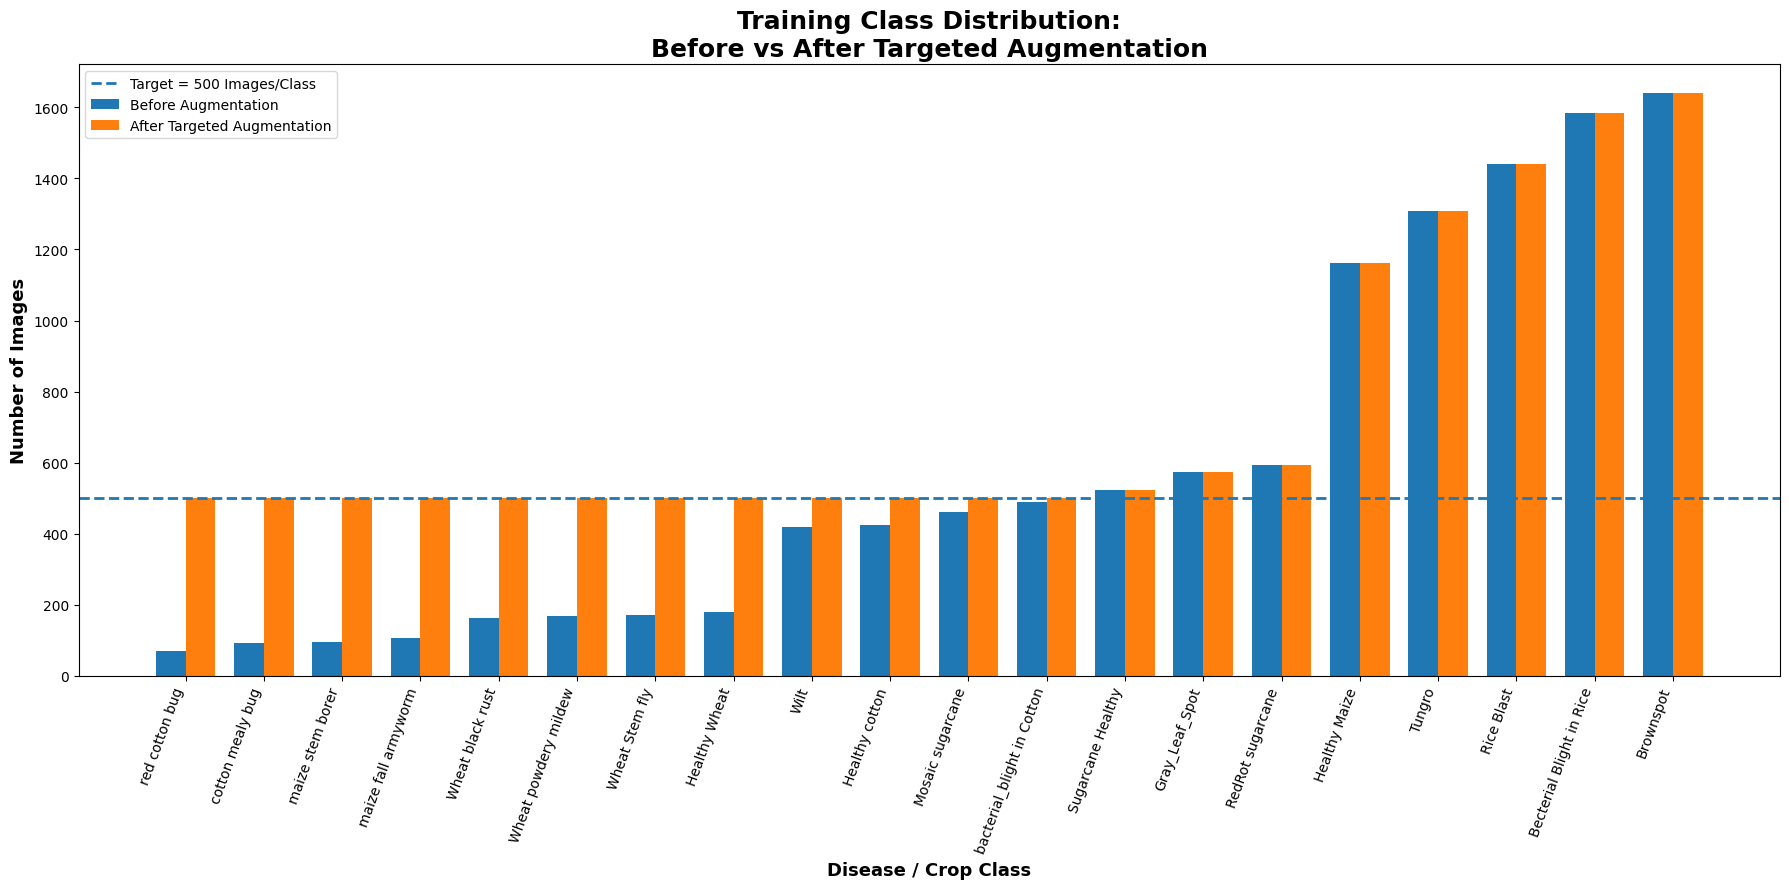

Saved:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/EDA/class_distribution_before_after_augmentation.png


In [50]:
# ============================================================
# CELL 17 - BEFORE vs AFTER CLASS DISTRIBUTION
# ============================================================

classes = final_distribution["Class"].values

before_counts = (
    final_distribution[
        "Before Augmentation"
    ].values
)

after_counts = (
    final_distribution[
        "After Targeted Augmentation"
    ].values
)

x = np.arange(len(classes))

width = 0.38

fig, ax = plt.subplots(
    figsize=(18, 9)
)

ax.bar(
    x - width / 2,
    before_counts,
    width,
    label="Before Augmentation"
)

ax.bar(
    x + width / 2,
    after_counts,
    width,
    label="After Targeted Augmentation"
)

ax.axhline(
    y=500,
    linestyle="--",
    linewidth=2,
    label="Target = 500 Images/Class"
)

ax.set_title(
    "Training Class Distribution:\n"
    "Before vs After Targeted Augmentation",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel(
    "Disease / Crop Class",
    fontsize=13,
    fontweight="bold"
)

ax.set_ylabel(
    "Number of Images",
    fontsize=13,
    fontweight="bold"
)

ax.set_xticks(x)

ax.set_xticklabels(
    classes,
    rotation=70,
    ha="right"
)

ax.legend()

plt.tight_layout()

class_distribution_path = os.path.join(
    MEMBER3_EDA,
    "class_distribution_before_after_augmentation.png"
)

plt.savefig(
    class_distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(class_distribution_path)

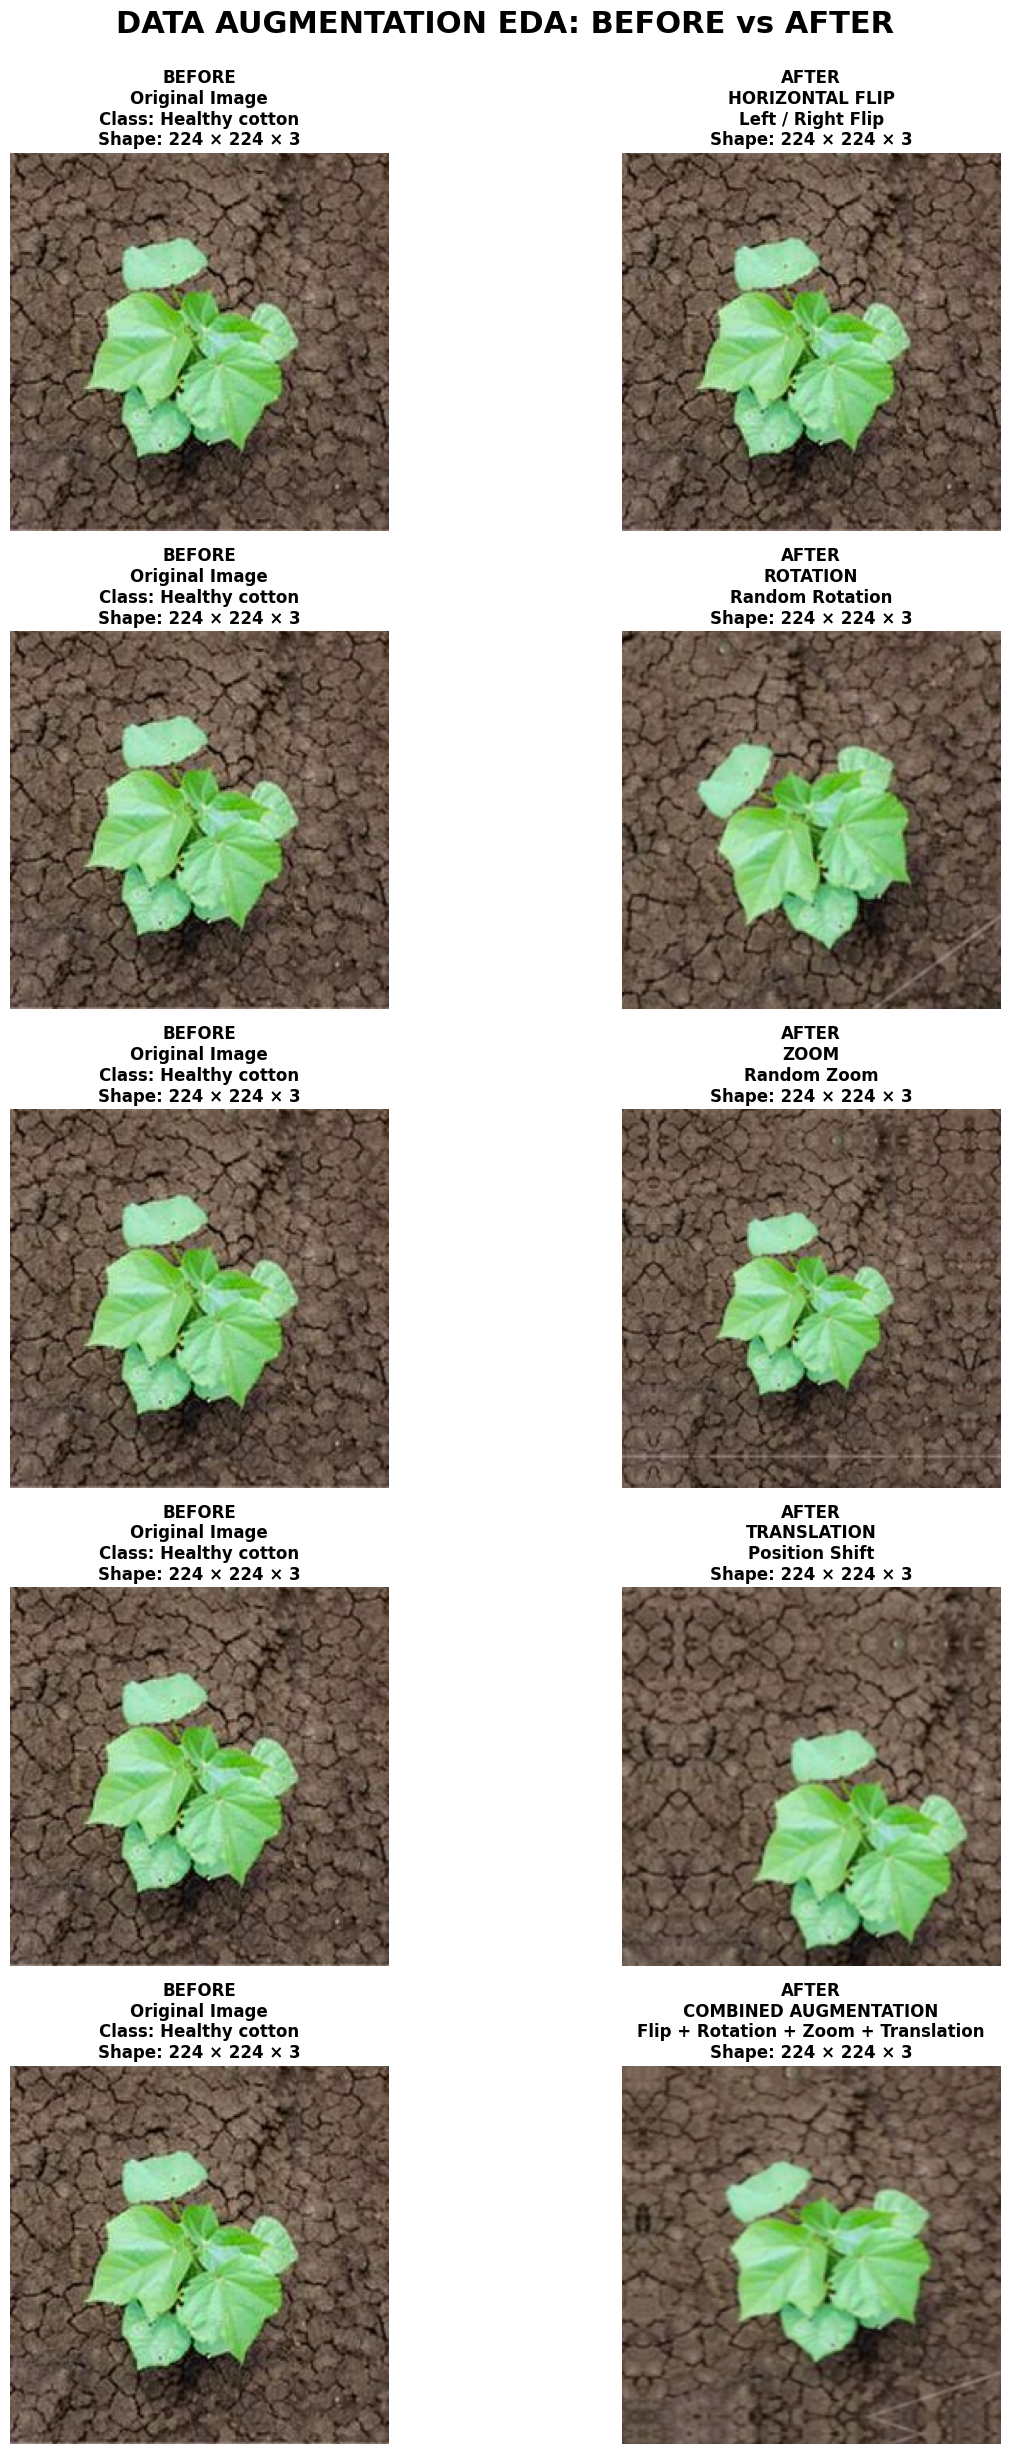

Saved:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/EDA/labeled_augmentation_before_after_eda.png


In [51]:
# ============================================================
# CELL 18 - LABELED BEFORE vs AFTER AUGMENTATION EDA
# ============================================================

preferred_classes = [
    "Healthy cotton",
    "Healthy Maize",
    "Healthy Wheat"
]

selected_index = None
selected_class = None

for class_name in preferred_classes:

    indices = np.where(
        train_labels == class_name
    )[0]

    if len(indices) > 0:

        selected_index = indices[
            len(indices) // 2
        ]

        selected_class = class_name

        break

if selected_index is None:

    selected_index = 0
    selected_class = train_labels[0]


original_image = train_images[
    selected_index
]

image_tensor = tf.convert_to_tensor(
    original_image,
    dtype=tf.float32
)

image_batch = tf.expand_dims(
    image_tensor,
    axis=0
)


# ------------------------------------------------------------
# Individual transformations
# ------------------------------------------------------------

flip_layer = tf.keras.layers.RandomFlip(
    mode="horizontal"
)

flipped = flip_layer(
    image_batch,
    training=True
)[0].numpy()


rotation_layer = tf.keras.layers.RandomRotation(
    factor=(0.10, 0.10),
    fill_mode="reflect"
)

rotated = rotation_layer(
    image_batch,
    training=True
)[0].numpy()


zoom_layer = tf.keras.layers.RandomZoom(
    height_factor=(0.20, 0.20),
    width_factor=(0.20, 0.20),
    fill_mode="reflect"
)

zoomed = zoom_layer(
    image_batch,
    training=True
)[0].numpy()


translation_layer = tf.keras.layers.RandomTranslation(
    height_factor=(0.15, 0.15),
    width_factor=(0.15, 0.15),
    fill_mode="reflect"
)

translated = translation_layer(
    image_batch,
    training=True
)[0].numpy()


combined = data_augmentation(
    image_batch,
    training=True
)[0].numpy()


# ------------------------------------------------------------
# Transformations list
# ------------------------------------------------------------

transformations = [

    (
        "HORIZONTAL FLIP",
        flipped,
        "Left / Right Flip"
    ),

    (
        "ROTATION",
        rotated,
        "Random Rotation"
    ),

    (
        "ZOOM",
        zoomed,
        "Random Zoom"
    ),

    (
        "TRANSLATION",
        translated,
        "Position Shift"
    ),

    (
        "COMBINED AUGMENTATION",
        combined,
        "Flip + Rotation + Zoom + Translation"
    )
]


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, axes = plt.subplots(
    5,
    2,
    figsize=(14, 25)
)

fig.suptitle(
    "DATA AUGMENTATION EDA: BEFORE vs AFTER",
    fontsize=22,
    fontweight="bold"
)

for row, (
    name,
    transformed,
    description
) in enumerate(transformations):

    axes[row, 0].imshow(
        np.clip(original_image, 0, 1)
    )

    axes[row, 0].set_title(
        "BEFORE\n"
        f"Original Image\n"
        f"Class: {selected_class}\n"
        "Shape: 224 × 224 × 3",
        fontsize=12,
        fontweight="bold"
    )

    axes[row, 0].axis("off")


    axes[row, 1].imshow(
        np.clip(transformed, 0, 1)
    )

    axes[row, 1].set_title(
        "AFTER\n"
        f"{name}\n"
        f"{description}\n"
        "Shape: 224 × 224 × 3",
        fontsize=12,
        fontweight="bold"
    )

    axes[row, 1].axis("off")


plt.tight_layout(
    rect=[0, 0, 1, 0.98]
)

augmentation_eda_path = os.path.join(
    MEMBER3_EDA,
    "labeled_augmentation_before_after_eda.png"
)

plt.savefig(
    augmentation_eda_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(augmentation_eda_path)

In [52]:
# ============================================================
# CELL 19 - SAVE FINAL DISTRIBUTION
# ============================================================

final_distribution_path = os.path.join(
    MEMBER3_OUTPUTS,
    "final_training_class_distribution.csv"
)

final_distribution.to_csv(
    final_distribution_path,
    index=False
)

print("Final distribution saved:")
print(final_distribution_path)

Final distribution saved:
/content/drive/MyDrive/Group_AIML/Member 03_IT25103371/Outputs/final_training_class_distribution.csv
